# Module 02: Blocking the Wrong Way
**Laying blocks parallel—instead of perpendicular—to a strong field gradient** · *~5 min*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lunganlungpg/experimental-design-gone-wrong/blob/main/02_blocking_the_wrong_way/02_blocking_the_wrong_way.ipynb)


## 1. The Setup (The Blunder)

A field agronomist plants a 32-plot wheat amendment trial (`Control`, `Biochar`, `Compost`, `NanoKelp`) on an 8-row × 4-column field next to a notoriously leaky irrigation canal along the West edge (`col_pos = 1` is lush and damp; `col_pos = 4` is bone-dry gravel). Remembering *something* from grad-school stats about blocking, they proudly mark out 8 horizontal **Row-blocks** (`Row_1` through `Row_8`) running West-to-East—**parallel** to the moisture cliff instead of perpendicular to it—and genuinely randomize the 4 treatments inside each row. Because every block spans from soggy swamp to desert, randomizing within rows completely fails to balance soil moisture across treatments, dealing `NanoKelp` to the wet West columns 6 out of 8 times.

In [1]:
# Works locally out of the box; in Google Colab, clones the repo for src/.
import subprocess
import sys
from pathlib import Path

GITHUB_REPO = "lunganlungpg/experimental-design-gone-wrong"

for root in (Path.cwd(), Path.cwd().parent):
    if (root / "src" / "simulate_blunders.py").exists():
        if str(root) not in sys.path:
            sys.path.insert(0, str(root))
        break
else:
    clone_dir = Path("/content/experimental-design-gone-wrong")
    if not clone_dir.exists():
        subprocess.run(
            ["git", "clone", "-q", f"https://github.com/{GITHUB_REPO}.git", str(clone_dir)],
            check=True,
        )
    sys.path.insert(0, str(clone_dir))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm

from src.simulate_blunders import (
    PALETTE,
    build_comparison_table,
    format_p_value,
    set_publication_style,
    simulate_blocking_the_wrong_way,
)

set_publication_style()
df = simulate_blocking_the_wrong_way(seed=11)
df.head(8)

,plot_id,row_num,row_block,col_pos,soil_moisture_pct,treatment,yield_t_ha
0,1,1,Row_1,1,35.5,NanoKelp,6.209
1,2,1,Row_1,2,30.0,Biochar,5.819
2,3,1,Row_1,3,24.9,Control,5.222
3,4,1,Row_1,4,17.8,Compost,4.818
4,5,2,Row_2,1,35.7,Control,6.328
5,6,2,Row_2,2,31.2,NanoKelp,5.478
6,7,2,Row_2,3,24.9,Biochar,5.095
7,8,2,Row_2,4,18.7,Compost,3.785


## 2. The Crime (Naive Analysis)

First, let's check both a **Naive CRD One-Way ANOVA** (`yield ~ treatment`) and the **Wrongly-Blocked RCBD** (`yield ~ treatment + row_block`). Neither model knows about the East-West canal gradient, so both fall head-over-heels for `NanoKelp`.

In [2]:
crd = smf.ols("yield_t_ha ~ C(treatment)", data=df).fit()
wrong_rcbd = smf.ols("yield_t_ha ~ C(treatment) + C(row_block)", data=df).fit()

aov_crd = anova_lm(crd)
aov_wrcbd = anova_lm(wrong_rcbd)

p_crd = float(aov_crd.loc["C(treatment)", "PR(>F)"])
p_wrcbd = float(aov_wrcbd.loc["C(treatment)", "PR(>F)"])

print(df.groupby("treatment", observed=True)[["yield_t_ha", "col_pos", "soil_moisture_pct"]].mean().round(2))
print(f"\nNaive CRD ANOVA        : F(3, {int(crd.df_resid)}) = {aov_crd.loc['C(treatment)', 'F']:.2f}, p = {format_p_value(p_crd)}")
print(f"Wrong-Blocked RCBD     : F(3, {int(wrong_rcbd.df_resid)}) = {aov_wrcbd.loc['C(treatment)', 'F']:.2f}, p = {format_p_value(p_wrcbd)}  <-- Wrong blocks helped 0%!")

           yield_t_ha  col_pos  soil_moisture_pct
treatment                                        
Control          4.97     2.88              26.28
Biochar          5.60     2.12              29.40
Compost          4.29     3.75              20.74
NanoKelp         6.05     1.25              34.48

Naive CRD ANOVA        : F(3, 28) = 12.90, p = 1.78e-05
Wrong-Blocked RCBD     : F(3, 21) = 10.22, p = 0.0002  <-- Wrong blocks helped 0%!


## 3. The Reality Check (Visual Punchline)

Left: the actual 8 × 4 field yield heatmap—the West-to-East canal cliff leaps off the page, and the dashed horizontal lines show how the Researcher's Row-blocks cut straight *across* it. Right: plotting each treatment's average yield against its unlucky average column position exposes the mirage.

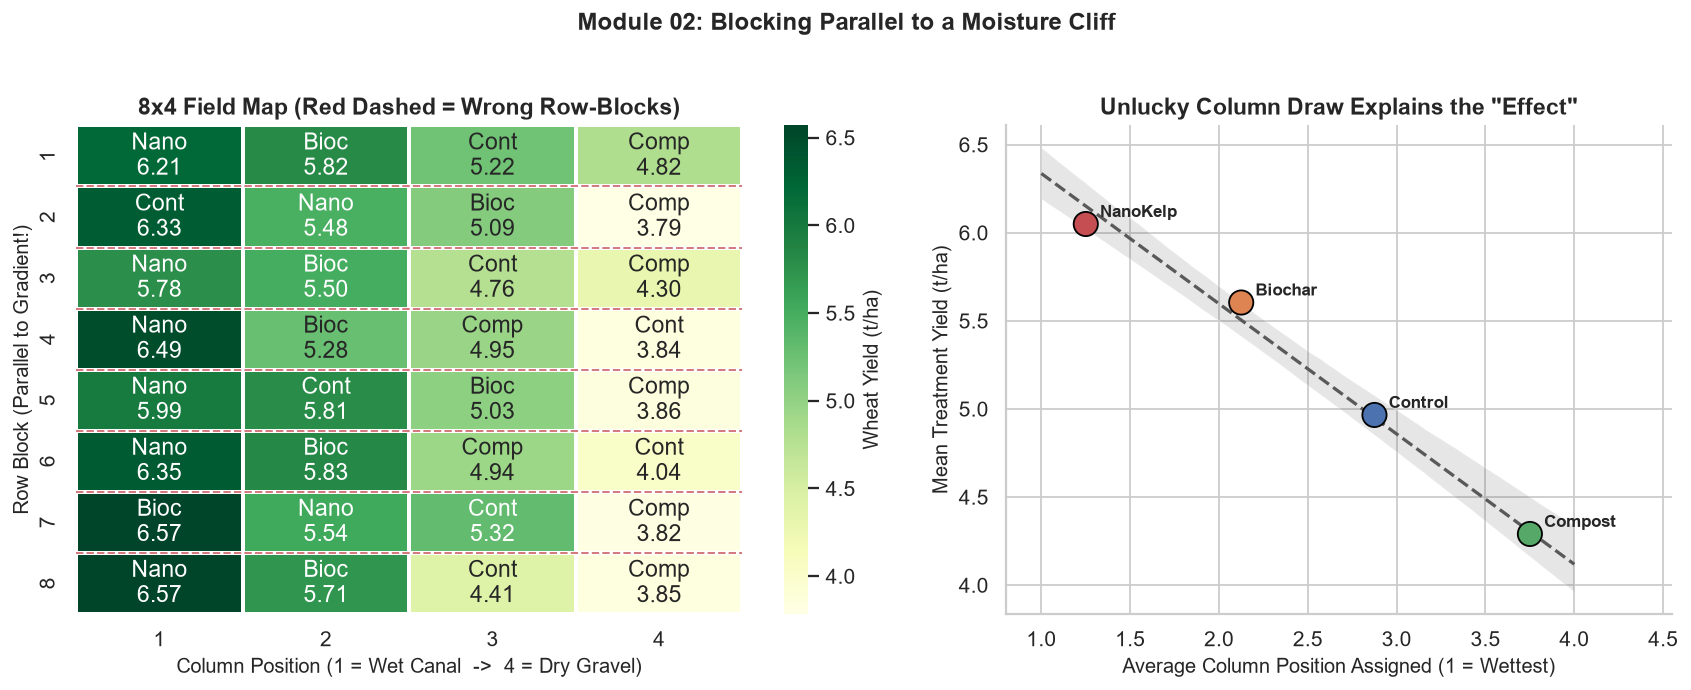

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13.2, 5.2), gridspec_kw={"width_ratios": [1.25, 1.0]})

# Panel A: Spatial Field Heatmap
yield_grid = df.pivot(index="row_num", columns="col_pos", values="yield_t_ha")
trt_grid = df.pivot(index="row_num", columns="col_pos", values="treatment")
annot_grid = yield_grid.copy().astype(str)
for r in yield_grid.index:
    for c in yield_grid.columns:
        abbr = str(trt_grid.loc[r, c])[:4]
        annot_grid.loc[r, c] = f"{abbr}\n{yield_grid.loc[r, c]:.2f}"

sns.heatmap(
    yield_grid, annot=annot_grid, fmt="", cmap="YlGn",
    cbar_kws={"label": "Wheat Yield (t/ha)"}, linewidths=1.2, linecolor="white", ax=axes[0]
)
# Highlight that rows were the wrong block boundaries
for y_line in range(1, 8):
    axes[0].axhline(y_line, color=PALETTE["danger"], ls="--", lw=1.1, alpha=0.75)
axes[0].set_title("8x4 Field Map (Red Dashed = Wrong Row-Blocks)")
axes[0].set_xlabel("Column Position (1 = Wet Canal  ->  4 = Dry Gravel)")
axes[0].set_ylabel("Row Block (Parallel to Gradient!)")

# Panel B: Mean Column Position vs Mean Yield
trt_summary = (
    df.groupby("treatment", as_index=False, observed=True)
    .agg(mean_yield=("yield_t_ha", "mean"), mean_col=("col_pos", "mean"))
)
sns.regplot(
    data=df, x="col_pos", y="yield_t_ha", scatter=False,
    color=PALETTE["neutral"], line_kws={"ls": "--", "lw": 1.8, "label": "Field Moisture Slope"}, ax=axes[1]
)
sns.scatterplot(
    data=trt_summary, x="mean_col", y="mean_yield", hue="treatment",
    s=180, edgecolor="black", linewidth=1.0, zorder=5, ax=axes[1]
)
for _, row in trt_summary.iterrows():
    axes[1].text(
        row["mean_col"] + 0.08, row["mean_yield"] + 0.04,
        row["treatment"], fontsize=9.5, fontweight="bold"
    )
axes[1].set_xlim(0.8, 4.55)
axes[1].set_title("Unlucky Column Draw Explains the \"Effect\"")
axes[1].set_xlabel("Average Column Position Assigned (1 = Wettest)")
axes[1].set_ylabel("Mean Treatment Yield (t/ha)")
axes[1].legend([], [], frameon=False)

fig.suptitle("Module 02: Blocking Parallel to a Moisture Cliff", fontsize=13.5, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## 4. The Fix (Proper Model)

Had the agronomist blocked **perpendicular** to the canal (using `col_pos` as the blocks), every treatment would have appeared once per column. Since this trial already happened, we can still rescue the inference by adding the perpendicular column factor (`C(col_pos)`) to form a **Row + Column Two-Way Blocked ANOVA** (`yield_t_ha ~ C(treatment) + C(row_block) + C(col_pos)`). Watch the fake `p = 0.0002` evaporate!

In [4]:
proper = smf.ols("yield_t_ha ~ C(treatment) + C(row_block) + C(col_pos)", data=df).fit()
aov_proper = anova_lm(proper, typ=2)
p_proper = float(aov_proper.loc["C(treatment)", "PR(>F)"])

contrast = "C(treatment)[T.NanoKelp]"
summary = build_comparison_table(
    [
        {
            "Model": "Naive CRD ANOVA",
            "Assumed Unit": "32 unblocked plots",
            "df_resid": int(crd.df_resid),
            "Estimate": f"{crd.params[contrast]:+.2f} t/ha (NanoKelp-Ctrl)",
            "95% CI": f"[{crd.conf_int().loc[contrast, 0]:+.2f}, {crd.conf_int().loc[contrast, 1]:+.2f}]",
            "p_value": format_p_value(p_crd),
            "Verdict": "Fooled by wet canal (p < 0.0001)",
        },
        {
            "Model": "Wrong-Blocked RCBD (Row blocks)",
            "Assumed Unit": "8 blocks parallel to canal",
            "df_resid": int(wrong_rcbd.df_resid),
            "Estimate": f"{wrong_rcbd.params[contrast]:+.2f} t/ha (NanoKelp-Ctrl)",
            "95% CI": f"[{wrong_rcbd.conf_int().loc[contrast, 0]:+.2f}, {wrong_rcbd.conf_int().loc[contrast, 1]:+.2f}]",
            "p_value": format_p_value(p_wrcbd),
            "Verdict": "Still fooled (p < 0.001)",
        },
        {
            "Model": "Proper Row + Column Model (+ col_pos)",
            "Assumed Unit": "32 plots w/ gradient controlled",
            "df_resid": int(proper.df_resid),
            "Estimate": f"{proper.params[contrast]:+.2f} t/ha (NanoKelp-Ctrl)",
            "95% CI": f"[{proper.conf_int().loc[contrast, 0]:+.2f}, {proper.conf_int().loc[contrast, 1]:+.2f}]",
            "p_value": format_p_value(p_proper),
            "Verdict": "Truth recovered (no effect)",
        },
    ]
)
summary

,Model,Assumed Unit,df_resid,Estimate,95% CI,p_value,Verdict
0,Naive CRD ANOVA,32 unblocked plots,28,+1.08 t/ha (NanoKelp-Ctrl),"[+0.47, +1.70]",1.78e-05,Fooled by wet canal (p < 0.0001)
1,Wrong-Blocked RCBD (Row blocks),8 blocks parallel to canal,21,+1.08 t/ha (NanoKelp-Ctrl),"[+0.38, +1.79]",0.0002,Still fooled (p < 0.001)
2,Proper Row + Column Model (+ col_pos),32 plots w/ gradient controlled,18,-0.14 t/ha (NanoKelp-Ctrl),"[-0.59, +0.30]",0.7258,Truth recovered (no effect)


> **Rule of Thumb:** Orient your blocks **perpendicular** to the strongest environmental gradient so every plot *inside* a block shares uniform soil, light, or slope—and if gradients run both ways, use a Latin Square. Blocking *parallel* to a gradient dumps all the environmental variation into your treatment residuals and leaves you at the mercy of an unlucky randomization draw.